# Horizon Retail | AI Opportunity & Strategy Analysis
### Reproducible Python decision-analysis portfolio
**CAIBL AI3120 — P101 inspired fictional case study** · Python · Pandas · Matplotlib · Seaborn · Pytest

> **Scope:** This notebook analyzes the fictional business case and the original submitted scoring judgments. It does not train a machine-learning model, access real customers, or report achieved pilot results.

**Core question:** Which single AI opportunity should Horizon Retail pilot first, and how robust is that choice?

## 1. Project objectives and evidence boundaries
- Compare four AI use cases with an auditable weighted scoring model.
- Examine business value, data readiness, feasibility, risk manageability and time to value.
- Demonstrate how one readiness assumption can reverse the recommended ranking.
- Design a bounded 90-day supervised pilot with proposed KPIs, budget and stop conditions.
- Produce reusable Python calculations, charts, CSV evidence and automated tests.

**Evidence categories:** (1) supplied fictional case facts; (2) original candidate scoring/budget judgments; (3) mathematically derived quantities; (4) new explanatory interpretation. These categories are not interchangeable.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'data' / 'case_inputs').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data' / 'case_inputs').exists(), 'Run from the repository or notebooks directory'
sys.path.insert(0, str(ROOT))
from src.scoring import weighted_score, rank_cases, scenario_override
CHARTS = ROOT / 'visualizations'; CHARTS.mkdir(exist_ok=True)
REPORTS = ROOT / 'reports'; REPORTS.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 180, 'axes.titlesize': 14, 'axes.labelsize': 10})
print('Python:', sys.version.split()[0], '| Pandas:', pd.__version__, '| NumPy:', np.__version__)
print('Project root:', ROOT)

def save_chart(name):
    plt.savefig(CHARTS / name, bbox_inches='tight', facecolor='white')
    plt.show()

Python: 3.14.8 | Pandas: 3.1.1 | NumPy: 2.5.5
Project root: C:\Rakesh Project\Horizon-Retail-AI-Opportunity-Strategy


## 2. Case context and key facts
Horizon Retail operates **12 stores**, generates **₹30 crore** in annual sales and has a **₹20 lakh first-year AI budget ceiling**. It may begin **one pilot**. Figures below are case-provided, not externally audited operational measurements.

In [2]:
case = json.loads((ROOT / 'data/case_inputs/case_facts.json').read_text(encoding='utf-8'))
facts = pd.DataFrame([
 ('Stores',case['stores'],'stores'),('Annual sales',case['annual_sales_inr_crore'],'₹ crore'),('First-year AI budget',case['first_year_ai_budget_inr_lakh'],'₹ lakh'),
 ('Inventory unavailability',case['inventory']['unavailable_requested_items_pct'],'% of requested items'),('Annual write-offs',case['inventory']['annual_writeoffs_inr_lakh'],'₹ lakh'),
 ('Missing stock-count entries',case['inventory']['missing_stock_count_entries_pct'],'%'),('Monthly enquiries',case['customer_enquiries']['monthly_enquiries'],'enquiries'),
 ('Average first response',case['customer_enquiries']['average_first_response_hours'],'hours'),('Routine policy enquiries',case['customer_enquiries']['routine_policy_enquiries_pct'],'%'),
 ('Marketing records',case['marketing']['customer_records'],'records'),('Marketing conversion',case['marketing']['conversion_pct'],'%'),
 ('Recorded marketing consent',case['marketing']['recorded_consent_pct'],'%'),('Shelf checking',case['store_inspection']['hours_per_store_per_day'],'hours/store/day')],columns=['Metric','Case value','Unit'])
display(facts)
facts.to_csv(REPORTS/'case_facts_table.csv',index=False)

,Metric,Case value,Unit
0,Stores,12,stores
1,Annual sales,30,₹ crore
2,First-year AI budget,20,₹ lakh
3,Inventory unavailability,6,% of requested items
4,Annual write-offs,45,₹ lakh
5,Missing stock-count entries,15,%
6,Monthly enquiries,8000,enquiries
7,Average first response,10,hours
8,Routine policy enquiries,60,%
9,Marketing records,50000,records


### 2.1 Useful derived quantities (not observed outcomes)
The arithmetic below helps define the potential pilot scope. It does **not** estimate realized cost savings or revenue uplift.

In [3]:
routine_per_month = case['customer_enquiries']['monthly_enquiries']*case['customer_enquiries']['routine_policy_enquiries_pct']/100
shelf_hours_per_day = case['stores']*case['store_inspection']['hours_per_store_per_day']
response_target_hours = case['customer_enquiries']['average_first_response_hours']*(1-.30)
derived = pd.DataFrame([('Routine policy enquiries / month',routine_per_month,'8,000 × 60%'),('Manual shelf-check hours / day',shelf_hours_per_day,'12 × 2'),('Proposed first-response target (hours)',response_target_hours,'10 × (1 − 30%)')],columns=['Derived quantity','Value','Formula'])
display(derived)

,Derived quantity,Value,Formula
0,Routine policy enquiries / month,4800.0,"8,000 × 60%"
1,Manual shelf-check hours / day,24.0,12 × 2
2,Proposed first-response target (hours),7.0,10 × (1 − 30%)


## 3. Four AI opportunity profiles
Each opportunity has a suitable AI approach, a simpler alternative and a readiness issue. The business should not treat AI as the default solution.

In [4]:
opportunities = pd.DataFrame([
 ('Inventory Demand Forecasting','Forecasting / supervised ML','Stock replenishment and write-offs','Sales and stock histories; product, store and time identifiers','15% missing stock-count entries','Improve stock counts and reorder-point rules'),
 ('Customer Enquiry Automation','Language AI / grounded response drafting','10-hour first-response delay; 60% routine policy queries','Current approved policies and representative enquiries','Policy accuracy, permission and test coverage unverified','Improve FAQs and response templates'),
 ('AI-Assisted Marketing','Segmentation / propensity modeling','2% campaign conversion','Consented customer records and campaign outcomes','Consent recorded for only 65%','Clean records and run consent-compliant manual segments'),
 ('AI-Assisted Store Inspection','Computer vision','2 hours/store/day manual shelf checks','Consistent, permissioned and labeled shelf images','No usable shelf-image dataset','Standardized digital inspection checklist')],columns=['Use case','AI approach','Business problem','Data required','Main readiness gap','Non-AI alternative'])
display(opportunities)
opportunities.to_csv(REPORTS/'use_case_comparison.csv',index=False)

,Use case,AI approach,Business problem,Data required,Main readiness gap,Non-AI alternative
0,Inventory Demand Forecasting,Forecasting / supervised ML,Stock replenishment and write-offs,"Sales and stock histories; product, store and ...",15% missing stock-count entries,Improve stock counts and reorder-point rules
1,Customer Enquiry Automation,Language AI / grounded response drafting,10-hour first-response delay; 60% routine poli...,Current approved policies and representative e...,"Policy accuracy, permission and test coverage ...",Improve FAQs and response templates
2,AI-Assisted Marketing,Segmentation / propensity modeling,2% campaign conversion,Consented customer records and campaign outcomes,Consent recorded for only 65%,Clean records and run consent-compliant manual...
3,AI-Assisted Store Inspection,Computer vision,2 hours/store/day manual shelf checks,"Consistent, permissioned and labeled shelf images",No usable shelf-image dataset,Standardized digital inspection checklist


## 4. Data-readiness assessment
**Availability ≠ suitability.** Historical records, consent flags, policy documents and images each require validation before operational AI use. Owners below are proposed roles, not confirmed appointments.

In [5]:
readiness = pd.DataFrame([
 ('Inventory','Inventory / merchandising owner','18 months of records; 15% stock-count gaps','Check completeness by store/product/time; reconcile counts; validate demand labels'),
 ('Customer enquiries','Customer service + policy owner','8,000 monthly enquiries; approved policy corpus not verified','Approve policy versions; prepare representative, privacy-reviewed test cases'),
 ('Marketing','Marketing + privacy owner','50,000 records; 65% consent recorded','Verify lawful purpose, consent scope, quality and suppression rules'),
 ('Shelf inspection','Store operations owner','No usable image dataset','Standardize inspections; assess permissioned image collection and labeling')],columns=['Area','Proposed owner','Known availability/gap','Pre-pilot closure action'])
display(readiness)
readiness.to_csv(REPORTS/'data_readiness.csv',index=False)

,Area,Proposed owner,Known availability/gap,Pre-pilot closure action
0,Inventory,Inventory / merchandising owner,18 months of records; 15% stock-count gaps,Check completeness by store/product/time; reco...
1,Customer enquiries,Customer service + policy owner,"8,000 monthly enquiries; approved policy corpu...",Approve policy versions; prepare representativ...
2,Marketing,Marketing + privacy owner,"50,000 records; 65% consent recorded","Verify lawful purpose, consent scope, quality ..."
3,Shelf inspection,Store operations owner,No usable image dataset,Standardize inspections; assess permissioned i...


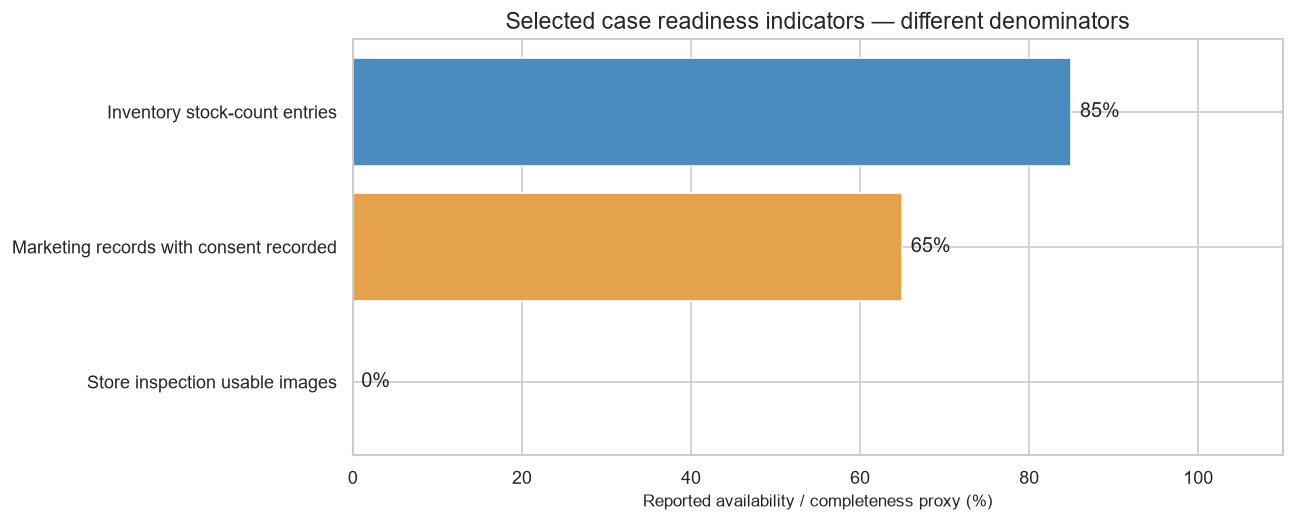

In [6]:
fig,ax=plt.subplots(figsize=(10,4.5))
areas=['Inventory stock-count entries','Marketing records with consent recorded','Store inspection usable images']
percent=[85,65,0]
bars=ax.barh(areas,percent,color=['#4B8BBE','#E4A24D','#C95D5D'])
ax.set_xlim(0,110);ax.set_xlabel('Reported availability / completeness proxy (%)')
ax.set_title('Selected case readiness indicators — different denominators')
for b,v in zip(bars,percent):ax.text(v+1,b.get_y()+b.get_height()/2,f'{v}%',va='center')
ax.invert_yaxis();save_chart('01_case_readiness_indicators.png')

**Interpretation:** These percentages refer to different populations and are **not** a common readiness score. The shelf-image indicator is a qualitative lack of a usable dataset represented as zero availability for visualization only; it is not a measured image-completeness percentage.

## 5. Weighted prioritization methodology
The original submitted decision matrix used a 1–5 criterion score and five weights. A higher score means a more attractive option. We reproduce those **candidate judgments**, rather than inventing new assessments.

In [7]:
scores_df=pd.read_csv(ROOT/'data/case_inputs/scoring.csv')
weights_df=pd.read_csv(ROOT/'data/case_inputs/weights.csv')
criteria=weights_df['Criterion'].tolist(); weights=weights_df['Weight'].tolist()
assert np.isclose(sum(weights),1.0)
assert scores_df[criteria].apply(lambda col: col.between(1,5).all()).all()
cases=[(row['Use Case'],[int(row[c]) for c in criteria]) for _,row in scores_df.iterrows()]
scores_df['Weighted Score']=[weighted_score(s,weights) for _,s in cases]
scores_df['Rank']=scores_df['Weighted Score'].rank(method='min',ascending=False).astype(int)
display(weights_df);display(scores_df.sort_values('Rank'))
assert dict(zip(scores_df['Use Case'],scores_df['Weighted Score']))=={'Inventory Demand Forecasting':3.6,'Customer Enquiry Automation':3.8,'AI-Assisted Marketing':2.95,'AI-Assisted Store Inspection':2.25}
scores_df.to_csv(REPORTS/'weighted_prioritization.csv',index=False)

,Criterion,Weight
0,Business Value,0.30
1,Data Readiness,0.20
2,Feasibility,0.20
3,Risk Manageability,0.15
4,Time to Value,0.15


,Use Case,Business Value,Data Readiness,Feasibility,Risk Manageability,Time to Value,Weighted Score,Rank
1,Customer Enquiry Automation,4,3,4,4,4,3.80,1
0,Inventory Demand Forecasting,5,3,3,3,3,3.60,2
2,AI-Assisted Marketing,4,2,3,2,3,2.95,3
3,AI-Assisted Store Inspection,3,1,2,3,2,2.25,4


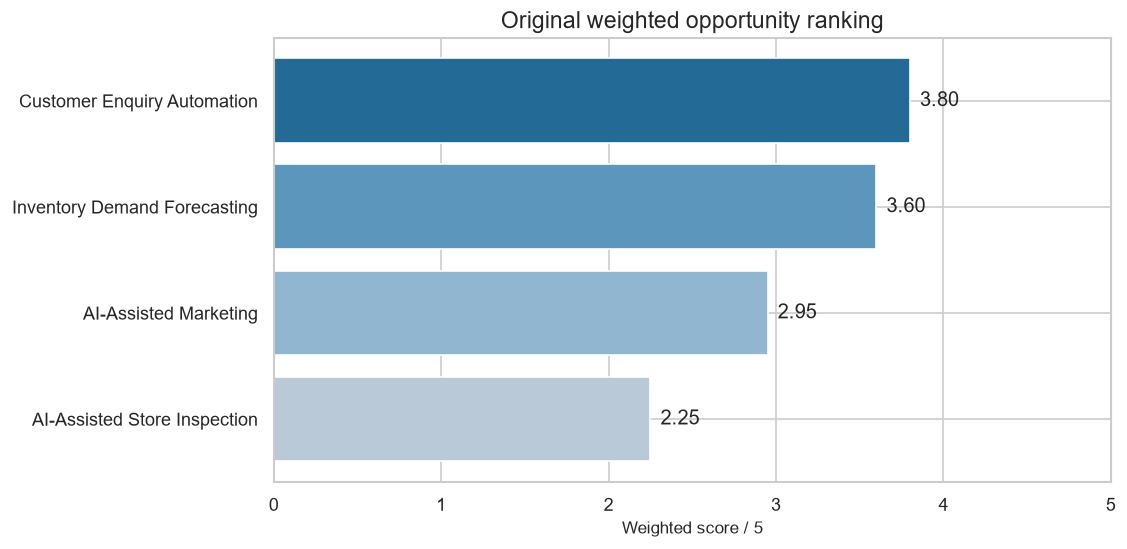

In [8]:
fig,ax=plt.subplots(figsize=(9,4.8))
ranked=scores_df.sort_values('Weighted Score')
bars=ax.barh(ranked['Use Case'],ranked['Weighted Score'],color=['#B9C9D7','#91B6CF','#5D96BD','#246A96'])
ax.set(xlim=(0,5),xlabel='Weighted score / 5',title='Original weighted opportunity ranking')
for b,v in zip(bars,ranked['Weighted Score']):ax.text(v+.06,b.get_y()+b.get_height()/2,f'{v:.2f}',va='center')
save_chart('02_weighted_ranking.png')

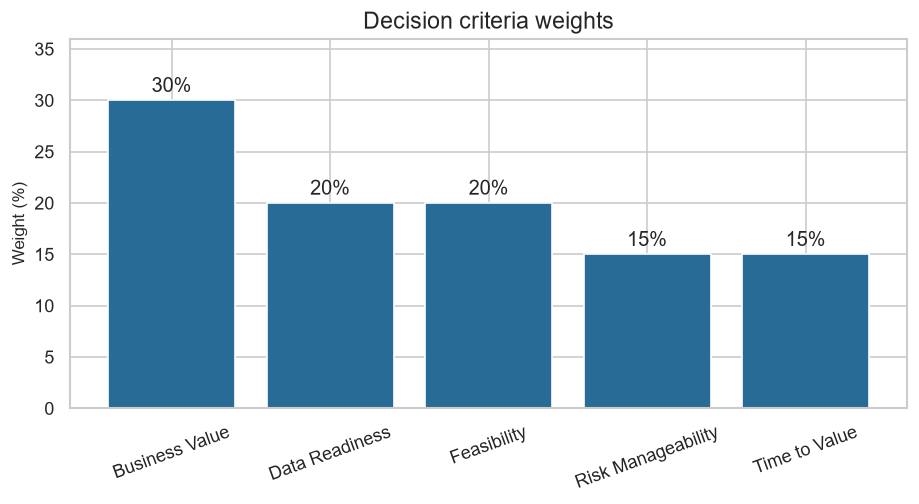

In [9]:
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(criteria,[w*100 for w in weights],color='#276B96')
ax.set(ylabel='Weight (%)',title='Decision criteria weights',ylim=(0,36))
ax.tick_params(axis='x',rotation=20)
for i,w in enumerate(weights):ax.text(i,w*100+.8,f'{w:.0%}',ha='center')
save_chart('03_criteria_weights.png')

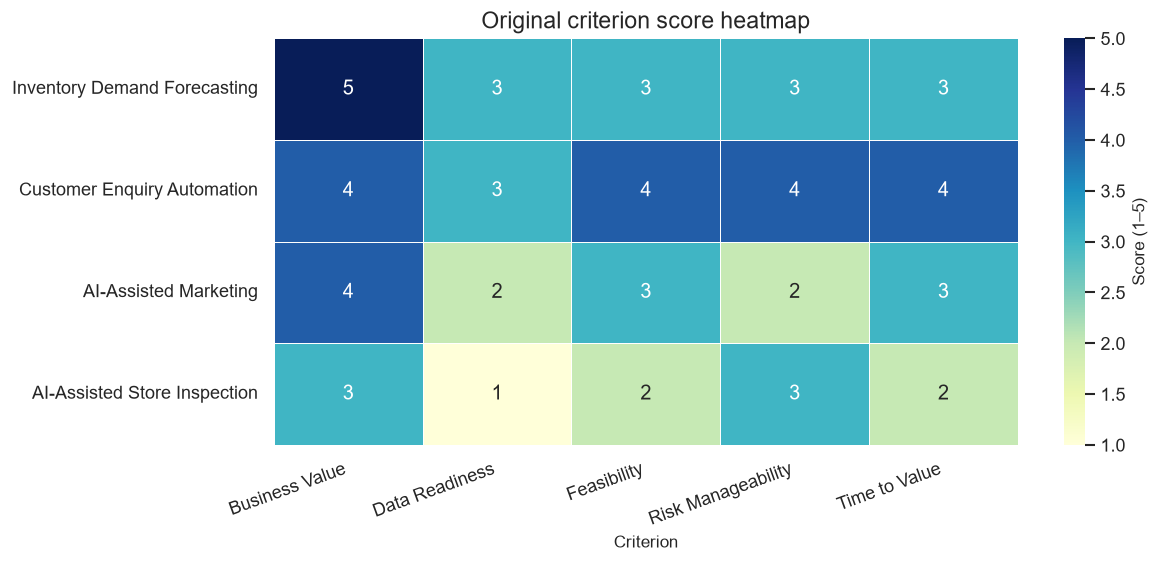

In [10]:
fig,ax=plt.subplots(figsize=(10,4.4))
sns.heatmap(scores_df.set_index('Use Case')[criteria],annot=True,fmt='.0f',cmap='YlGnBu',vmin=1,vmax=5,linewidths=.6,ax=ax,cbar_kws={'label':'Score (1–5)'})
ax.set(title='Original criterion score heatmap',xlabel='Criterion',ylabel='');plt.xticks(rotation=20,ha='right')
save_chart('04_scoring_heatmap.png')

### 5.1 Score rationale register
These explanations are **portfolio interpretations of the submitted scores**, not a claim that the original spreadsheet contained all these narrative justifications. They should be treated as qualitative judgments requiring validation.

In [11]:
rationale=pd.read_csv(ROOT/'data/case_inputs/score_rationales.csv')
assert len(rationale)==20
display(rationale)
rationale.to_csv(REPORTS/'score_rationales_table.csv',index=False)

,Use Case,Criterion,Original score,Portfolio rationale (interpretive)
0,Inventory Demand Forecasting,Business Value,5,Large write-offs and item unavailability creat...
1,Inventory Demand Forecasting,Data Readiness,3,"18 months of records exist, but 15% of stock-c..."
2,Inventory Demand Forecasting,Feasibility,3,Possible after reconciliation and forecasting ...
3,Inventory Demand Forecasting,Risk Manageability,3,Forecast errors and replenishment decisions re...
4,Inventory Demand Forecasting,Time to Value,3,A 90-day evaluation is plausible after data re...
5,Customer Enquiry Automation,Business Value,4,High enquiry volume and long response delays s...
6,Customer Enquiry Automation,Data Readiness,3,Policy sources and representative test enquiri...
7,Customer Enquiry Automation,Feasibility,4,Limited staff-reviewed drafting is feasible wi...
8,Customer Enquiry Automation,Risk Manageability,4,"Human approval and escalation can constrain, n..."
9,Customer Enquiry Automation,Time to Value,4,Routine questions offer an early measurable su...


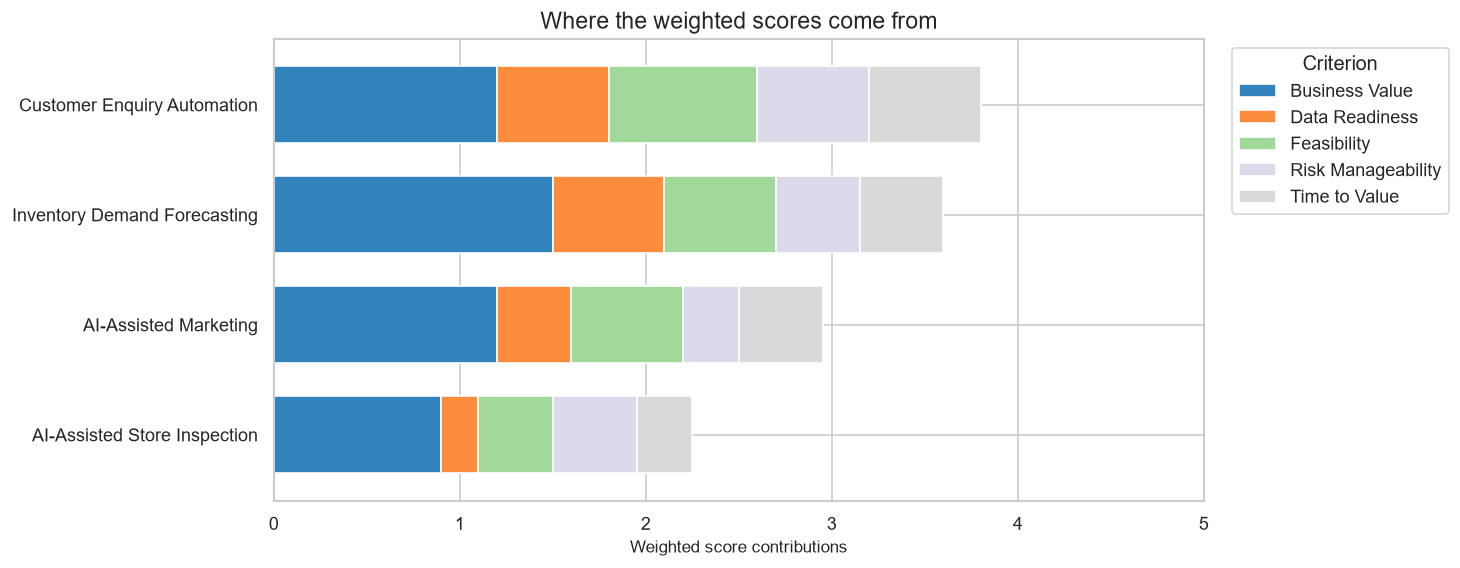

In [12]:
contrib=scores_df.set_index('Use Case')[criteria].mul(pd.Series(weights,index=criteria),axis=1)
fig,ax=plt.subplots(figsize=(10,5))
contrib.loc[scores_df.sort_values('Weighted Score')['Use Case']].plot.barh(stacked=True,ax=ax,colormap='tab20c',width=.7)
ax.set(xlim=(0,5),xlabel='Weighted score contributions',title='Where the weighted scores come from',ylabel='')
ax.legend(title='Criterion',bbox_to_anchor=(1.02,1),loc='upper left')
save_chart('05_weighted_score_contributions.png')

## 6. Sensitivity analysis: a decision that changes
**Submitted assumption change:** If suitable approved customer policy information cannot be validated, Customer Enquiry Automation data readiness is revised **3 → 1**, holding all other criterion scores and weights fixed.

In [13]:
revised_cases=scenario_override(cases,'Customer Enquiry Automation',criteria.index('Data Readiness'),1)
original_rank=rank_cases(cases,weights); revised_rank=rank_cases(revised_cases,weights)
orig={r['Use Case']:r['Weighted Score'] for r in original_rank}
rev={r['Use Case']:r['Weighted Score'] for r in revised_rank}
sensitivity=pd.DataFrame([{'Use Case':n,'Original score':orig[n],'Revised score':rev[n],'Original rank':next(i for i,r in enumerate(original_rank,1) if r['Use Case']==n),'Revised rank':next(i for i,r in enumerate(revised_rank,1) if r['Use Case']==n)} for n,_ in cases])
display(sensitivity.sort_values('Original rank'))
assert rev['Customer Enquiry Automation']==3.4
assert revised_rank[0]['Use Case']=='Inventory Demand Forecasting'
sensitivity.to_csv(REPORTS/'sensitivity_comparison.csv',index=False)

,Use Case,Original score,Revised score,Original rank,Revised rank
1,Customer Enquiry Automation,3.80,3.40,1,2
0,Inventory Demand Forecasting,3.60,3.60,2,1
2,AI-Assisted Marketing,2.95,2.95,3,3
3,AI-Assisted Store Inspection,2.25,2.25,4,4


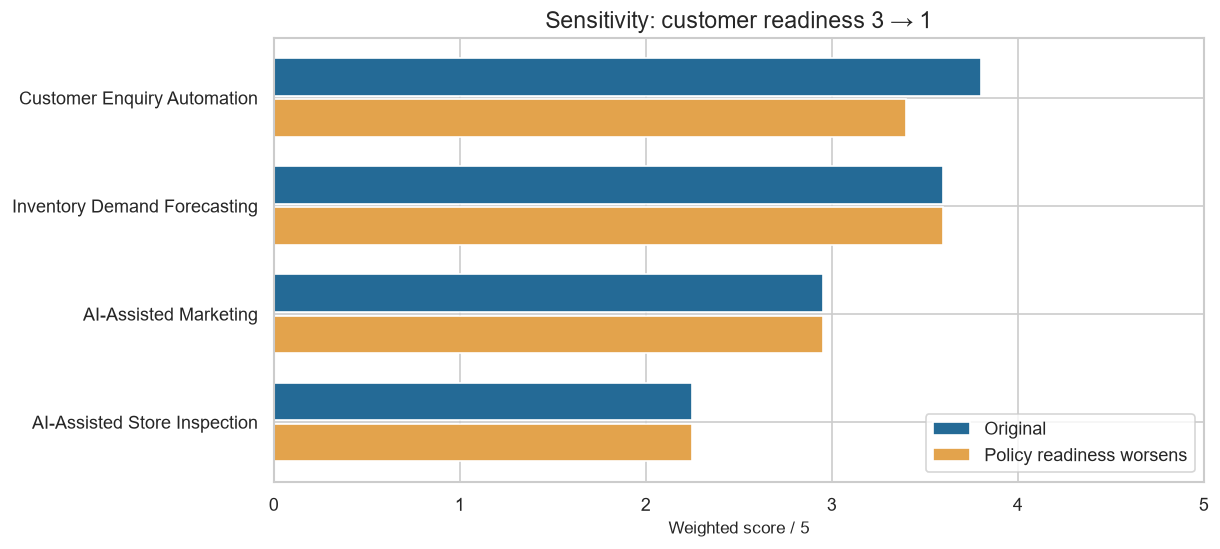

In [14]:
s=sensitivity.sort_values('Original rank'); y=np.arange(len(s));fig,ax=plt.subplots(figsize=(10,4.8))
ax.barh(y-.19,s['Original score'],height=.35,label='Original',color='#246A96')
ax.barh(y+.19,s['Revised score'],height=.35,label='Policy readiness worsens',color='#E3A34C')
ax.set(yticks=y,yticklabels=s['Use Case'],xlim=(0,5),xlabel='Weighted score / 5',title='Sensitivity: customer readiness 3 → 1')
ax.invert_yaxis();ax.legend(loc='lower right');save_chart('06_sensitivity_ranking.png')

,Customer readiness score,Customer weighted score,Inventory weighted score
0,1,3.4,3.6
1,2,3.6,3.6
2,3,3.8,3.6
3,4,4.0,3.6
4,5,4.2,3.6


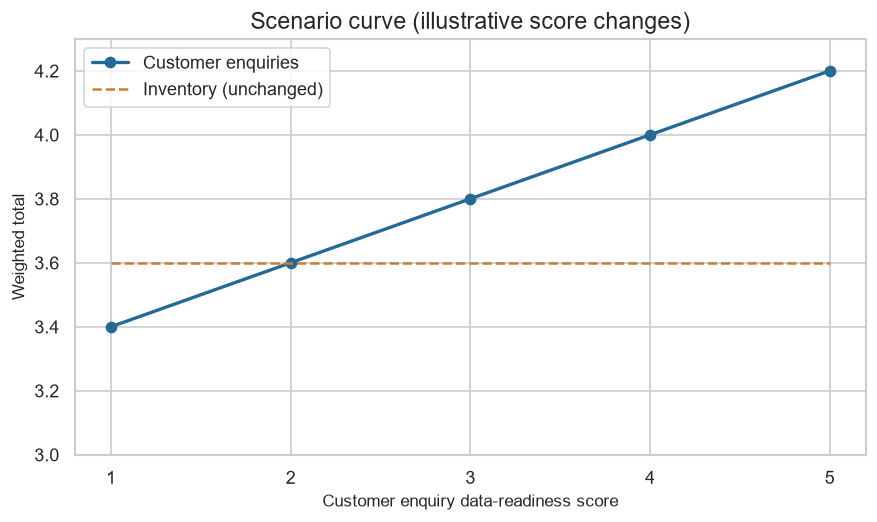

In [15]:
trial=[]
for readiness_score in range(1,6):
    sc=scenario_override(cases,'Customer Enquiry Automation',1,readiness_score)
    trial.append({'Customer readiness score':readiness_score,'Customer weighted score':dict((r['Use Case'],r['Weighted Score']) for r in rank_cases(sc,weights))['Customer Enquiry Automation'],'Inventory weighted score':orig['Inventory Demand Forecasting']})
readiness_curve=pd.DataFrame(trial);display(readiness_curve)
fig,ax=plt.subplots(figsize=(8.5,4.5))
ax.plot(readiness_curve['Customer readiness score'],readiness_curve['Customer weighted score'],marker='o',label='Customer enquiries',lw=2,color='#246A96')
ax.plot(readiness_curve['Customer readiness score'],readiness_curve['Inventory weighted score'],linestyle='--',label='Inventory (unchanged)',color='#C87E33')
ax.set(xticks=[1,2,3,4,5],xlabel='Customer enquiry data-readiness score',ylabel='Weighted total',title='Scenario curve (illustrative score changes)',ylim=(3,4.3))
ax.legend();save_chart('07_readiness_scenario_curve.png')

**Interpretation:** A change of 2 points in a criterion weighted at 20% reduces the total by 0.40. The preferred option changes. This is a deterministic **what-if test**, not a forecast, confidence interval or measured pilot result. Inventory is a fallback candidate only after its own stock-data validation.

## 7. Recommended 90-day pilot: staff-reviewed response drafting
**Purpose:** Test whether grounded language AI can help staff draft routine delivery, returns and product-policy responses.

**Included:** approved policy content, representative test questions, staff-reviewed drafts, escalation logging and monitoring.

**Excluded:** auto-sending replies, autonomous refunds, policy exceptions, unsupported answers, sensitive cases and unapproved personal data.

**Non-AI comparison:** improved FAQs and standardized response templates.

**Human control:** 100% of AI-generated drafts must be reviewed and approved before sending; stop/pause for critical privacy issues or repeated unsupported answers.

In [16]:
roadmap=pd.DataFrame([
 ('Days 1–30','Readiness and baselines','Confirm policies, data permissions, staff ownership, test cases and baseline','Go only if source accuracy, privacy and escalation controls are acceptable'),
 ('Days 31–60','Controlled testing','Test draft quality, unsupported answers, escalations and staff workflow','Revise or pause if accuracy/controls fail; no unsupervised sending'),
 ('Days 61–90','Supervised pilot and evaluation','Monitor response times, review accuracy, cost, incidents and non-AI comparator','Continue, revise or stop based on measured evidence and approver decision')],columns=['Phase','Focus','Evidence to collect','Decision gate'])
display(roadmap);roadmap.to_csv(REPORTS/'90_day_roadmap.csv',index=False)

,Phase,Focus,Evidence to collect,Decision gate
0,Days 1–30,Readiness and baselines,"Confirm policies, data permissions, staff owne...","Go only if source accuracy, privacy and escala..."
1,Days 31–60,Controlled testing,"Test draft quality, unsupported answers, escal...",Revise or pause if accuracy/controls fail; no ...
2,Days 61–90,Supervised pilot and evaluation,"Monitor response times, review accuracy, cost,...","Continue, revise or stop based on measured evi..."


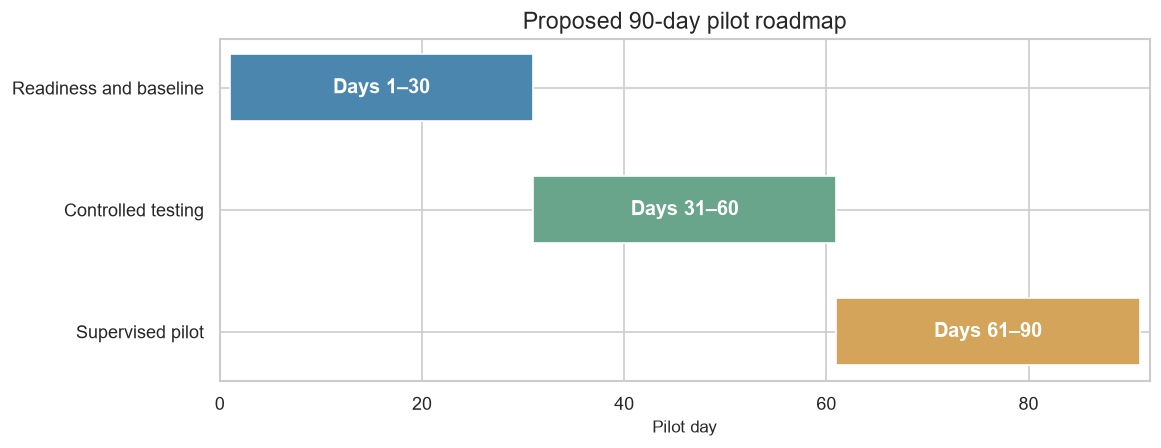

In [17]:
fig,ax=plt.subplots(figsize=(10,3.7))
phases=[('Readiness and baseline',1,30,'#4A86AD'),('Controlled testing',31,30,'#68A58A'),('Supervised pilot',61,30,'#D4A45A')]
for i,(name,start,duration,color) in enumerate(phases):
 ax.barh(i,duration,left=start,height=.55,color=color)
 ax.text(start+duration/2,i,f'Days {start}–{start+duration-1}',ha='center',va='center',color='white',weight='bold')
ax.set(yticks=range(3),yticklabels=[p[0] for p in phases],xlim=(0,92),xlabel='Pilot day',title='Proposed 90-day pilot roadmap')
ax.invert_yaxis();save_chart('08_90_day_roadmap.png')

## 8. Proposed budget and KPI framework
Budget figures are **planning allocations from the submitted charter**, not quotes, expenditure or approved vendor contracts.

In [18]:
budget=pd.read_csv(ROOT/'data/case_inputs/budget.csv');display(budget)
assert budget['Planning INR lakh'].sum()==20
budget.to_csv(REPORTS/'budget_breakdown.csv',index=False)

,Category,Planning INR lakh
0,Setup and configuration,4
1,Data preparation and policy validation,3
2,Integration and access controls,4
3,Staff training and testing,2
4,First-year operating costs,4
5,Contingency reserve,3


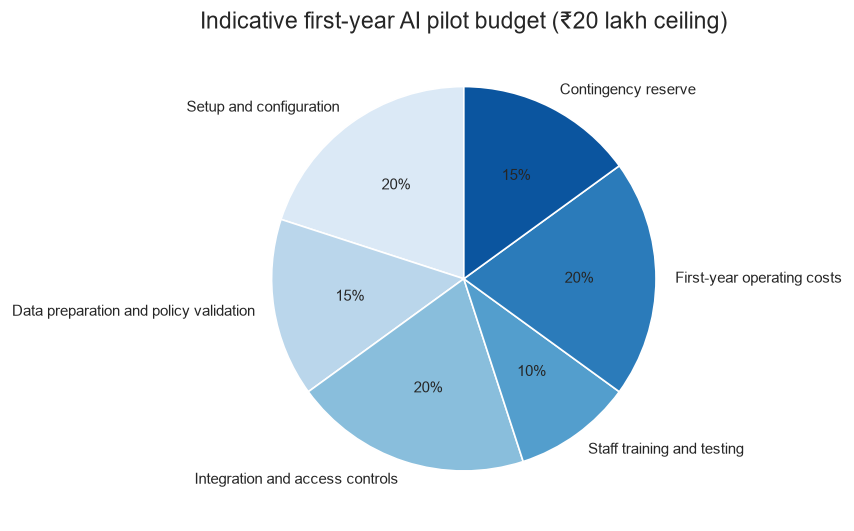

In [19]:
fig,ax=plt.subplots(figsize=(8.5,5.2))
ax.pie(budget['Planning INR lakh'],labels=budget['Category'],autopct=lambda p:f'{p:.0f}%',startangle=90,textprops={'fontsize':9},colors=sns.color_palette('Blues',n_colors=6))
ax.set_title('Indicative first-year AI pilot budget (₹20 lakh ceiling)')
save_chart('09_budget_allocation.png')

In [20]:
kpis=pd.DataFrame([
 ('Average first-response delay','Hours per enquiry','10 hours','≤7 hours (≥30% reduction)','Timestamped enquiry logs','Customer service owner','Weekly','Investigate bottlenecks; revise workflow'),
 ('Policy-grounded answer accuracy','Correct reviewed drafts / reviewed drafts','Not measured','≥95%','Reviewed and labeled draft sample','Policy owner','Weekly','Pause or revise if unsupported drafts recur'),
 ('Required human escalation','Escalated flagged cases / flagged cases','Not measured','100%','Escalation register','Customer service owner','Weekly','Pause and correct missed escalations'),
 ('Staff approval','Approved drafts / sent AI-assisted replies','Not measured','100%','Approval audit log','Customer service owner','Weekly','Stop unauthorized auto-sends'),
 ('Unresolved critical privacy incidents','Count','Not measured','0','Privacy incident log','Privacy owner','Immediate','Pause pilot and investigate'),
 ('Budget ceiling','₹ lakh first-year committed + spent','No actual expenditure reported','≤20','Finance records','Sponsor / finance','At each gate','Re-scope or seek approval')],columns=['Measure','Unit and denominator','Case baseline / status','Proposed target','Evidence source','Proposed owner','Cadence','Action if missed'])
display(kpis);kpis.to_csv(REPORTS/'proposed_kpi_register.csv',index=False)

,Measure,Unit and denominator,Case baseline / status,Proposed target,Evidence source,Proposed owner,Cadence,Action if missed
0,Average first-response delay,Hours per enquiry,10 hours,≤7 hours (≥30% reduction),Timestamped enquiry logs,Customer service owner,Weekly,Investigate bottlenecks; revise workflow
1,Policy-grounded answer accuracy,Correct reviewed drafts / reviewed drafts,Not measured,≥95%,Reviewed and labeled draft sample,Policy owner,Weekly,Pause or revise if unsupported drafts recur
2,Required human escalation,Escalated flagged cases / flagged cases,Not measured,100%,Escalation register,Customer service owner,Weekly,Pause and correct missed escalations
3,Staff approval,Approved drafts / sent AI-assisted replies,Not measured,100%,Approval audit log,Customer service owner,Weekly,Stop unauthorized auto-sends
4,Unresolved critical privacy incidents,Count,Not measured,0,Privacy incident log,Privacy owner,Immediate,Pause pilot and investigate
5,Budget ceiling,₹ lakh first-year committed + spent,No actual expenditure reported,≤20,Finance records,Sponsor / finance,At each gate,Re-scope or seek approval


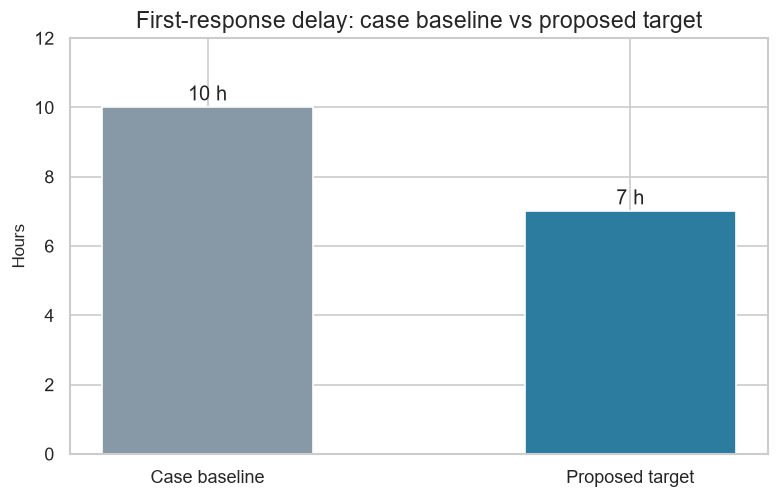

In [21]:
fig,ax=plt.subplots(figsize=(7.5,4.5))
ax.bar(['Case baseline','Proposed target'],[10,7],color=['#8799A7','#2B7C9F'],width=.5)
ax.set(ylabel='Hours',title='First-response delay: case baseline vs proposed target',ylim=(0,12))
for i,v in enumerate([10,7]):ax.text(i,v+.2,f'{v} h',ha='center')
save_chart('10_response_time_target.png')

## 9. Current and proposed process (conceptual)
**Current state is a simplified assumption**, because the supplied case does not document a verified step-by-step current workflow. The proposed process reflects the submitted pilot charter's staff-review controls.

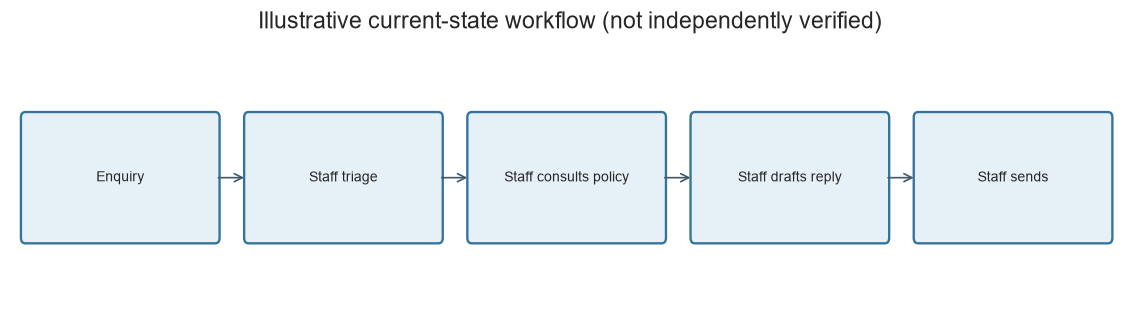

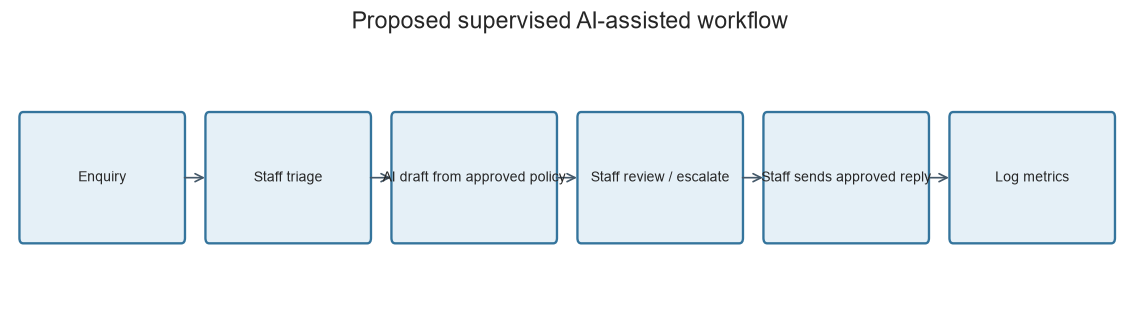

In [22]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
def draw_flow(labels,title,filename):
 fig,ax=plt.subplots(figsize=(12,2.9));ax.set_xlim(0,len(labels));ax.set_ylim(0,1);ax.axis('off')
 for i,label in enumerate(labels):
  rect=FancyBboxPatch((i+.06,.28),.85,.45,boxstyle='round,pad=0.02',facecolor='#E5F0F7',edgecolor='#34749C',linewidth=1.4)
  ax.add_patch(rect);ax.text(i+.485,.505,label,ha='center',va='center',fontsize=8.4,wrap=True)
  if i<len(labels)-1:ax.add_patch(FancyArrowPatch((i+.91,.505),(i+1.055,.505),arrowstyle='->',mutation_scale=12,color='#445869'))
 ax.set_title(title,pad=10,fontsize=14);save_chart(filename)
draw_flow(['Enquiry','Staff triage','Staff consults policy','Staff drafts reply','Staff sends'], 'Illustrative current-state workflow (not independently verified)','11_current_process_assumed.png')
draw_flow(['Enquiry','Staff triage','AI draft from approved policy','Staff review / escalate','Staff sends approved reply','Log metrics'], 'Proposed supervised AI-assisted workflow','12_proposed_process.png')

## 10. Final recommendation, decision gates and limitations
**Conditional recommendation:** Begin with **Customer Enquiry Automation**, subject to validated approved policies, suitable test enquiries, privacy controls and responsible staff ownership. Its initial weighted score is **3.80/5**. Inventory is **3.60/5** and becomes first when customer readiness falls from 3 to 1.

**Gate 1 (Day 30):** Confirm readiness and baseline; pause if policy or privacy conditions fail.

**Gate 2 (Day 60):** Review controlled test quality and escalation; revise or pause if safety fails.

**Gate 3 (Day 90):** Continue, revise or stop using measured KPIs, cost, risk and non-AI comparison.

**Limitations:** No raw data, no observed AI outcomes, no verified vendor costs, subjective scores, no proven financial ROI, and no implementation of the proposed AI assistant. The analysis supports a **pilot decision**, not a deployment claim.

## 11. Reproducibility and verification
The scoring module is independently tested with `pytest`. The notebook verifies the original submitted totals, the revised customer score, ranking reversal and the ₹20 lakh budget. It saves reproducible CSV tables and PNG charts.

**Local command:** `python -m pytest -q` from the repository root.

**References:** Supplied IABAC CAIBL AI3120 P101 fictional case brief; candidate's previously submitted v1 scoring matrix, report and pilot charter. The original documents are not redistributed in this public portfolio package.

**Disclosure:** AI assistance was used to develop and structure this portfolio extension; calculations and claims must be independently verified before publication.

## 12. My development approach and tools

I treated this as a **small, reproducible Python analysis**, not as a production AI deployment. I first checked the supplied business facts, then organized the scores and weights as input files, wrote a reusable scoring function, compared the ranking with the submitted assessment, and tested how changing an assumption affected the decision.

| Tool | Why I used it | Evidence in this repository |
|---|---|---|
| Jupyter Notebook | Explain each calculation and display outputs together | This notebook |
| Python | Implement calculations and input checks | `src/scoring.py` |
| Pandas / NumPy | Organize and compare tabular inputs | Notebook cells and CSV reports |
| Matplotlib / Seaborn | Explain rankings, contributions and trade-offs | `visualizations/` |
| Excel | Original assessment scoring reference; cross-check the totals | Documented source scores; original workbook is not redistributed |
| Pytest | Verify known results and invalid-input behavior | `tests/test_scoring.py` |
| PowerShell | Set up and run the project on Windows | `run_all.ps1` |
| Git / GitHub | Track and publish a reproducible portfolio | To be verified after local push |

**Tools intentionally not claimed:** MySQL, FastAPI, Power BI, Tableau and ML model training are not implemented here. Those belong in separate engineering projects.

## 13. Step-by-step validation and engineering habits

I learned that an analysis is stronger when it can be checked independently. I used three checks: (1) confirm the scoring weights total 100%, (2) reproduce the four original weighted scores, and (3) verify that the sensitivity case changes the ranking as described.

A second lesson was to keep **case facts**, **subjective evaluation scores**, **planning targets** and **actual results** separate. For example, 8,000 enquiries per month is a supplied case fact, whereas a 30% reduction in first-response time is a *proposed target*, not a measured improvement.

For software engineering, the scoring function lives in `src/scoring.py` rather than only in a notebook cell. This makes it easier to import, test and reuse. The test suite should be rerun after any change to the weights, inputs or logic.

## 14. Challenges and lessons learned

**Challenge: Comparing different business opportunities fairly.** Inventory, marketing, customer service and inspection have different units and benefits. A weighted scoring framework gave them a common decision scale, but the scores remain judgments rather than objective measurements.

**Challenge: Avoiding misleading comparisons.** The 15% missing inventory counts and 65% recorded marketing consent describe different populations; they should not be compared as if they were identical data-quality metrics.

**Challenge: Checking whether the recommendation is robust.** The initial top score was 3.80/5 for customer enquiries, but lowering its readiness score from 3 to 1 changes the leader to inventory (3.60 versus 3.40). That made the recommendation conditional rather than absolute.

**What I would improve next:** Obtain approved operational data, establish measured baselines, define owners and permissions, and compare the proposed AI pilot with improved FAQ/templates. These are **future activities**, not completed tests.

**Local execution notes:** Record actual installation errors, corrections and test outputs in `documentation/LOCAL_VERIFICATION.md` after running the project on Windows. Do not invent a debugging history.

## 15. How this connects to my backend-development learning path

This project gave me practice with **functions, modules, data validation, file organization, tests and reproducible outputs**. These are useful foundations for Python backend development.

A future, separately scoped project could expose ranking calculations through REST endpoints and persist scenarios in a relational database. I have **not** implemented or tested those features in this repository, so they are not listed as completed work.

## 16. Responsible AI use and authorship

AI-assisted tools were used to help structure and refine the portfolio notebook, documentation and code. The published project should retain this disclosure rather than trying to disguise assistance. The case facts and original decision figures came from the submitted fictional assessment; calculations are reproducible in Python and tests. The learner should personally review the notebook, run the tests locally and be able to explain the weighted-score formula, scenario change and limitations before describing this as independent proficiency.

**Publication boundary:** This portfolio does not reproduce the copyrighted assessment brief, private submission materials or personal learner identifiers. No AI assistant was deployed for Horizon Retail, and no real customer data or measured pilot results are included.